<a href="https://colab.research.google.com/github/alokchoudharyguliya/ML/blob/main/CNN%20Keras%20Vehicle/%5BLearning%5DCNN_Keras_Vehicle.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

KerasDataset

In [ ]:
import tensorflow as tf
from tensorflow.keras import datasets, layers, models
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [ ]:
(X_train,y_train),(X_test,y_test)=datasets.cifar10.load_data()
X_train.shape

(50000, 32, 32, 3)

In [ ]:
X_test.shape

(10000, 32, 32, 3)

In [ ]:
y_train.shape
y_train

array([[6],
       [9],
       [9],
       ...,
       [9],
       [1],
       [1]], dtype=uint8)

In [ ]:
y_train=y_train.reshape(-1,)
y_train

array([6, 9, 9, ..., 9, 1, 1], dtype=uint8)

In [ ]:
X_train[0]


array([[[ 59,  62,  63],
        [ 43,  46,  45],
        [ 50,  48,  43],
        ...,
        [158, 132, 108],
        [152, 125, 102],
        [148, 124, 103]],

       [[ 16,  20,  20],
        [  0,   0,   0],
        [ 18,   8,   0],
        ...,
        [123,  88,  55],
        [119,  83,  50],
        [122,  87,  57]],

       [[ 25,  24,  21],
        [ 16,   7,   0],
        [ 49,  27,   8],
        ...,
        [118,  84,  50],
        [120,  84,  50],
        [109,  73,  42]],

       ...,

       [[208, 170,  96],
        [201, 153,  34],
        [198, 161,  26],
        ...,
        [160, 133,  70],
        [ 56,  31,   7],
        [ 53,  34,  20]],

       [[180, 139,  96],
        [173, 123,  42],
        [186, 144,  30],
        ...,
        [184, 148,  94],
        [ 97,  62,  34],
        [ 83,  53,  34]],

       [[177, 144, 116],
        [168, 129,  94],
        [179, 142,  87],
        ...,
        [216, 184, 140],
        [151, 118,  84],
        [123,  92,  72]]

In [ ]:
classes=["airplane","automobile","bird","cat","deer","dog","frog","horse","ship","truck"]

In [ ]:
def plot_sample(X, y, index):
  plt.figure(figsize=(15,2))
  plt.imshow(X[index])
  plt.xlabel(classes[y[index]])

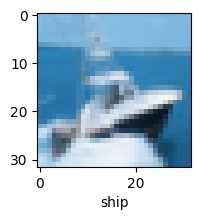

In [ ]:
plot_sample(X_train,y_train,8)

In [ ]:
# pixel values originally vary from 0-255 and to normalize them we divide this by 255 to get values ranging from 0-1
X_train=X_train/255

In [ ]:
X_train

array([[[[0.23137255, 0.24313725, 0.24705882],
         [0.16862745, 0.18039216, 0.17647059],
         [0.19607843, 0.18823529, 0.16862745],
         ...,
         [0.61960784, 0.51764706, 0.42352941],
         [0.59607843, 0.49019608, 0.4       ],
         [0.58039216, 0.48627451, 0.40392157]],

        [[0.0627451 , 0.07843137, 0.07843137],
         [0.        , 0.        , 0.        ],
         [0.07058824, 0.03137255, 0.        ],
         ...,
         [0.48235294, 0.34509804, 0.21568627],
         [0.46666667, 0.3254902 , 0.19607843],
         [0.47843137, 0.34117647, 0.22352941]],

        [[0.09803922, 0.09411765, 0.08235294],
         [0.0627451 , 0.02745098, 0.        ],
         [0.19215686, 0.10588235, 0.03137255],
         ...,
         [0.4627451 , 0.32941176, 0.19607843],
         [0.47058824, 0.32941176, 0.19607843],
         [0.42745098, 0.28627451, 0.16470588]],

        ...,

        [[0.81568627, 0.66666667, 0.37647059],
         [0.78823529, 0.6       , 0.13333333]

In [ ]:
X_test=X_test/255

In [ ]:
ann=models.Sequential([
    layers.Flatten(input_shape=(32,32,3)),
    layers.Dense(3000,activation='relu'),
    layers.Dense(1000,activation='relu'),
    layers.Dense(10,activation='sigmoid')

    # using the keras api we create artificial neural network
    # keras.layers.Flatten(input_shape=(32,32,3)),
    # keras.layers.Dense(3000,activation='relu'),
    # keras.layers.Dense(1000,activation='relu'),
    # keras.layers.Dense(10,activation='sigmoid')
])
ann.compile(optimizer='SGD',loss='sparse_categorical_crossentropy',metrics=['accuracy'])
ann.fit(X_train,y_train,epochs=5)


Epoch 1/5
1563/1563 [==============================] - 7s 4ms/step - loss: 1.8118 - accuracy: 0.3563
Epoch 2/5
1563/1563 [==============================] - 7s 4ms/step - loss: 1.6227 - accuracy: 0.4266
Epoch 3/5
1563/1563 [==============================] - 6s 4ms/step - loss: 1.5415 - accuracy: 0.4560
Epoch 4/5
1563/1563 [==============================] - 7s 4ms/step - loss: 1.4785 - accuracy: 0.4790
Epoch 5/5
1563/1563 [==============================] - 6s 4ms/step - loss: 1.4325 - accuracy: 0.4946


In [ ]:
y_predict=ann.predict(X_test)

313/313 [==============================] - 1s 2ms/step


In [ ]:
y_predict[0]

array([0.4128578 , 0.39407492, 0.6835883 , 0.907728  , 0.4946204 ,
       0.7996379 , 0.8368445 , 0.09814151, 0.57692814, 0.09595084],
      dtype=float32)

In [ ]:
y_test[0]

array([3], dtype=uint8)

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report
y_pred=ann.predict(X_test)
y_pred_classes=[np.argmax(element) for element in y_pred]
print("Classification Report:\n",classification_report(y_test,y_pred_classes))

313/313 [==============================] - 1s 2ms/step
Classification Report:
               precision    recall  f1-score   support

           0       0.49      0.65      0.56      1000
           1       0.67      0.56      0.61      1000
           2       0.44      0.26      0.33      1000
           3       0.35      0.34      0.34      1000
           4       0.47      0.34      0.40      1000
           5       0.41      0.35      0.38      1000
           6       0.47      0.65      0.55      1000
           7       0.42      0.69      0.52      1000
           8       0.67      0.53      0.59      1000
           9       0.61      0.52      0.56      1000

    accuracy                           0.49     10000
   macro avg       0.50      0.49      0.48     10000
weighted avg       0.50      0.49      0.48     10000



In [ ]:
# score of ann on this image classification is very low
# now we will try CNN
cnn=models.Sequential([
    # cnn
    layers.Conv2D(filters=32,kernel_size=(3,3),activation='relu',input_shape=(32,32,3)),
    layers.MaxPooling2D((2,2)),

    layers.Conv2D(filters=64,kernel_size=(3,3),activation='relu'),
    layers.MaxPooling2D((2,2)),

    # dense
    layers.Flatten(),
    layers.Dense(64,activation='relu'),
    layers.Dense(10,activation='softmax')
])

In [ ]:
cnn.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

In [ ]:
cnn.fit(X_train,y_train,epochs=10)

Epoch 1/10
1563/1563 [==============================] - 8s 4ms/step - loss: 1.4289 - accuracy: 0.4864
Epoch 2/10
1563/1563 [==============================] - 7s 5ms/step - loss: 1.0816 - accuracy: 0.6222
Epoch 3/10
1563/1563 [==============================] - 6s 4ms/step - loss: 0.9615 - accuracy: 0.6667
Epoch 4/10
1563/1563 [==============================] - 7s 4ms/step - loss: 0.8728 - accuracy: 0.6968
Epoch 5/10
1563/1563 [==============================] - 6s 4ms/step - loss: 0.8037 - accuracy: 0.7200
Epoch 6/10
1563/1563 [==============================] - 7s 5ms/step - loss: 0.7417 - accuracy: 0.7411
Epoch 7/10
1563/1563 [==============================] - 8s 5ms/step - loss: 0.6877 - accuracy: 0.7629
Epoch 8/10
1563/1563 [==============================] - 6s 4ms/step - loss: 0.6404 - accuracy: 0.7770
Epoch 9/10
1563/1563 [==============================] - 7s 4ms/step - loss: 0.5979 - accuracy: 0.7908
Epoch 10/10
1563/1563 [==============================] - 6s 4ms/step - loss: 0.557

In [ ]:
cnn.evaluate(X_test,y_test)

313/313 [==============================] - 2s 5ms/step - loss: 0.9231 - accuracy: 0.7020


[0.9230746030807495, 0.7020000219345093]

In [ ]:
y_test=y_test.reshape(-1,)

In [ ]:
y_predc=cnn.predict(X_test)
y_predc_classes=[np.argmax(element) for element in y_predc]
print("Classification Report:\n",classification_report(y_test,y_predc_classes))

313/313 [==============================] - 1s 2ms/step
Classification Report:
               precision    recall  f1-score   support

           0       0.74      0.73      0.74      1000
           1       0.83      0.82      0.82      1000
           2       0.53      0.65      0.59      1000
           3       0.56      0.47      0.51      1000
           4       0.74      0.56      0.64      1000
           5       0.64      0.57      0.60      1000
           6       0.72      0.82      0.77      1000
           7       0.72      0.78      0.75      1000
           8       0.81      0.80      0.81      1000
           9       0.75      0.81      0.78      1000

    accuracy                           0.70     10000
   macro avg       0.70      0.70      0.70     10000
weighted avg       0.70      0.70      0.70     10000



In [ ]:
y_predc_classes[0]

3

In [ ]:
y_test[0]

3